# CS 6625 – Machine Learning-Based Phishing URL Detection

**Student Name:** Shawn Walker

## Week 2: Dataset Exploration

In [1]:
# Part 3: Install the UCI Dataset Package

!pip install -q ucimlrepo

In [2]:
# Part 4: Import Python Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

In [3]:
# Part 5: Load the phiUSIL Dataset

phiusiil = fetch_ucirepo(id=967)

X = phiusiil.data.features.copy()
y = phiusiil.data.targets.squeeze().copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (235795, 54)
Target shape: (235795,)


In [4]:
# Part 7: Examine the First Rows

pd.set_option("display.max_columns", 12)

X.head()

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,...,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,...,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,...,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,...,10,2,7,42,2,5
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,...,3,27,15,22,1,31
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,...,244,15,34,72,1,85


In [5]:
# Part 8: Examine Feature Names

print(X.columns.tolist())

['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [6]:
# Part 9: Examine the Labels

print(y.value_counts())

label
1    134850
0    100945
Name: count, dtype: int64


In [7]:
# Part 10: Why Label Meaning Matters

class_counts = y.value_counts().sort_index()

print(class_counts)

label
0    100945
1    134850
Name: count, dtype: int64


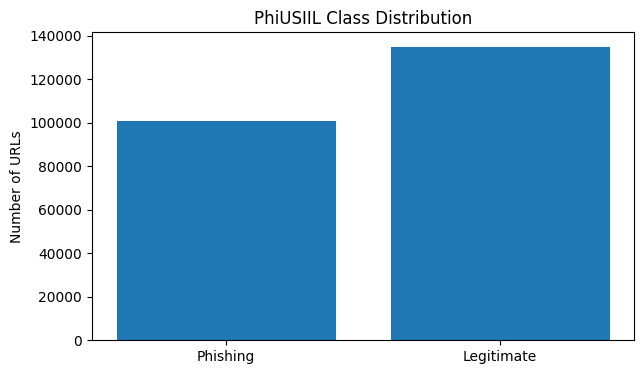

In [8]:
# Part 11: Examine Class Distribution

labels = ["Phishing", "Legitimate"]

counts = [
    class_counts.loc[0],
    class_counts.loc[1]
]

plt.figure(figsize=(7, 4))
plt.bar(labels, counts)

plt.ylabel("Number of URLs")
plt.title("PhiUSIIL Class Distribution")

plt.show()

In [9]:
# Part 13: Examine Data Types

print(X.dtypes.value_counts())

int64      40
float64    10
object      4
Name: count, dtype: int64


In [10]:
# Part 14: Check for Missing Values

missing_total = X.isna().sum().sum()

print(
    "Total missing feature values:",
    missing_total
)

Total missing feature values: 0


In [11]:
# Part 15: Descriptive Statistics

X.describe()


,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,...,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,...,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,...,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,...,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,...,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000


In [12]:
X.select_dtypes(
    include=np.number
).describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6097.000000
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,110.000000
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,100.000000
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,0.522907
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,0.090824
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,13.000000
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,10.000000
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000


In [13]:
# Part 16: Compare URL Length

analysis_df = X[
    ["URLLength", "DomainLength", "IsDomainIP"]
].copy()

analysis_df["Label"] = y.values

analysis_df.groupby(
    "Label"
)["URLLength"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
Label,,,,,
0,100945,45.720293,34.0,13,6097
1,134850,26.228610,26.0,15,57


In [14]:
# Part 17: Compare Domain Length

analysis_df.groupby(
    "Label"
)["DomainLength"].agg(
    ["mean", "median", "min", "max"]
)

,mean,median,min,max
Label,,,,
0,24.465144,22.0,4,110
1,19.228610,19.0,8,50


In [15]:
# Part 18: Examine IsDomainIP

pd.crosstab(
    analysis_df["Label"],
    analysis_df["IsDomainIP"],
    normalize="index"
)

IsDomainIP,0,1
Label,,
0,0.99368,0.00632
1,1.00000,0.00000


# Week 3: Data Preparation and Train/Test Split

In [16]:
#Part 3: Load the Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split

phiusiil = fetch_ucirepo(id=967)

X_raw = phiusiil.data.features.copy()
y_original = phiusiil.data.targets.squeeze().copy()

print(X_raw.shape)
print(y_original.shape)


(235795, 54)
(235795,)


In [17]:
# Part 4: Recode the Target

y = (y_original == 0).astype(int)

y.name = "Phishing"

print(y.value_counts())

Phishing
0    134850
1    100945
Name: count, dtype: int64


In [18]:
# Part 5: Select Numeric Features

X = X_raw.select_dtypes(
    include=np.number
).copy()

print(X.shape)

print(X.columns.tolist())


(235795, 50)
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [19]:
# Part 6: Verify the Data

print(
    "Number of X rows:",
    len(X)
)

print(
    "Number of y values:",
    len(y)
)

print(
    "Missing values:",
    X.isna().sum().sum()
)

Number of X rows: 235795
Number of y values: 235795
Missing values: 0


In [20]:
# Part 7: Explore Selected Features

selected_features = [
    "URLLength",
    "DomainLength",
    "URLSimilarityIndex",
    "CharContinuationRate",
    "TLDLegitimateProb"
]

X[selected_features].describe().T


,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6097.000000
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,110.000000
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,100.000000
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,0.522907


In [21]:
# Part 8: Compare Features by Class

analysis_df = X[
    selected_features
].copy()

analysis_df["Phishing"] = y.values

analysis_df.groupby(
    "Phishing"
)[selected_features].mean().T

Phishing,0,1
URLLength,26.228610,45.720293
DomainLength,19.228610,24.465144
URLSimilarityIndex,100.000000,49.616973
CharContinuationRate,0.933176,0.728395
TLDLegitimateProb,0.281625,0.232099


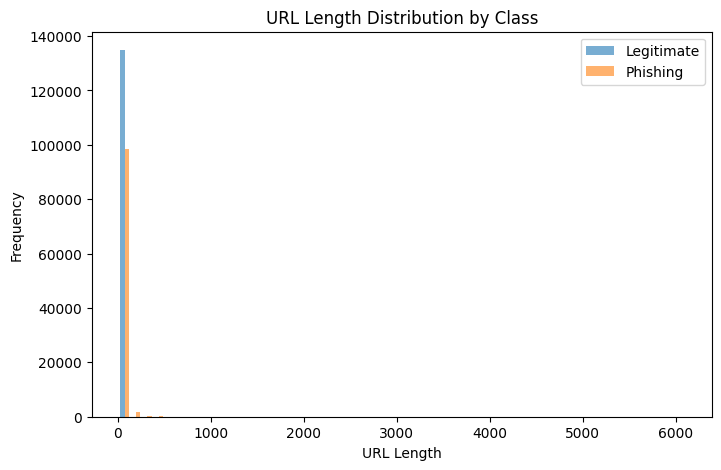

In [22]:
# Part 9: Visualize URL Length

legitimate_url_length = analysis_df.loc[
    analysis_df["Phishing"] == 0,
    "URLLength"
]

phishing_url_length = analysis_df.loc[
    analysis_df["Phishing"] == 1,
    "URLLength"
]

plt.figure(figsize=(8, 5))

plt.hist(
    [
        legitimate_url_length,
        phishing_url_length
    ],
    bins=50,
    label=[
        "Legitimate",
        "Phishing"
    ],
    alpha=0.6
)

plt.xlabel("URL Length")
plt.ylabel("Frequency")

plt.title(
    "URL Length Distribution by Class"
)

plt.legend()

plt.show()

In [23]:

# Part 11: Create the Official Course Split

from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)



In [24]:

# Part 12: What Does test_size=0.20 Mean?

print(
    "X_train:",
    X_train.shape
)

print(
    "X_test:",
    X_test.shape
)


X_train: (188636, 50)
X_test: (47159, 50)


In [25]:

# Part 15: Verify Class Distribution

print(
    "Full dataset:"
)

print(
    y.value_counts(
        normalize=True
    )
)


Full dataset:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [26]:

print(
    "Training:"
)

print(
    y_train.value_counts(
        normalize=True
    )
)

Training:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [27]:

print(
    "Testing:"
)

print(
    y_test.value_counts(
        normalize=True
    )
)


Testing:
Phishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64


In [28]:

# Part 16: Verify Reproducibility

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print(
    X_train.index.equals(
        X_train2.index
    )
)

print(
    X_test.index.equals(
        X_test2.index
    )
)



True
True


In [29]:

# Part 19: Correct Scaling Procedure

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)


# Week 4: Logistic Regression and Classification Metrics

In [30]:
# Part 7: Build the Pipeline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000
        )
    )
])

In [31]:
# Part 8: Train the Model

lr_model.fit(
    X_train,
    y_train
)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=2000))])

In [32]:
# Part 9: Generate Predictions

lr_pred = lr_model.predict(
    X_test
)

print(
    lr_pred[:20]
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


In [33]:
print(
    y_test.iloc[:20].to_numpy()
)

[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


In [34]:
# Part 10: Prediction vs. Probability

lr_prob = lr_model.predict_proba(
    X_test
)[:, 1]

print(
    lr_prob[:10]
)

[7.76971563e-07 9.99999753e-01 1.85108133e-04 1.00000000e+00
 8.82577634e-05 3.54717718e-07 9.99711349e-01 9.99999574e-01
 6.63741195e-14 6.65616758e-09]


In [35]:
# Part 11: Preview Predictions and Probabilities

probability_preview = pd.DataFrame({
    "Actual":
        y_test.iloc[:10].to_numpy(),

    "Predicted":
        lr_pred[:10],

    "Phishing Probability":
        lr_prob[:10]
})

probability_preview

,Actual,Predicted,Phishing Probability
0,0,0,7.769716e-07
1,1,1,9.999998e-01
2,0,0,1.851081e-04
3,1,1,1.000000e+00
4,0,0,8.825776e-05
5,0,0,3.547177e-07
6,1,1,9.997113e-01
7,1,1,9.999996e-01
8,0,0,6.637412e-14
9,0,0,6.656168e-09


In [36]:
# Part 12: Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

lr_precision = precision_score(
    y_test,
    lr_pred
)

lr_recall = recall_score(
    y_test,
    lr_pred
)

lr_f1 = f1_score(
    y_test,
    lr_pred
)

lr_auc = roc_auc_score(
    y_test,
    lr_prob
)

print(
    f"Accuracy : {lr_accuracy:.4f}"
)

print(
    f"Precision: {lr_precision:.4f}"
)

print(
    f"Recall   : {lr_recall:.4f}"
)

print(
    f"F1-score : {lr_f1:.4f}"
)

print(
    f"ROC-AUC  : {lr_auc:.4f}"
)

Accuracy : 0.9999
Precision: 1.0000
Recall   : 0.9998
F1-score : 0.9999
ROC-AUC  : 1.0000


In [37]:
# Part 18: Confusion Matrix

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_test,
    lr_pred
)

print(cm)

[[26970     0]
 [    5 20184]]


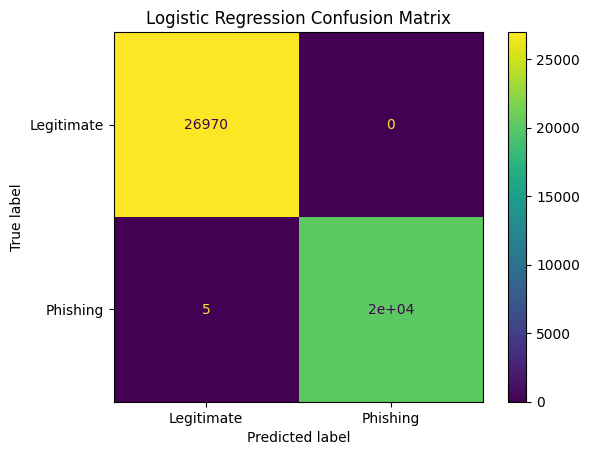

In [38]:
# Part 20: Display the Confusion Matrix

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
).plot()

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.show()

In [39]:
# Part 22: Classification Report

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        lr_pred,
        target_names=[
            "Legitimate",
            "Phishing"
        ]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     26970
    Phishing       1.00      1.00      1.00     20189

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159



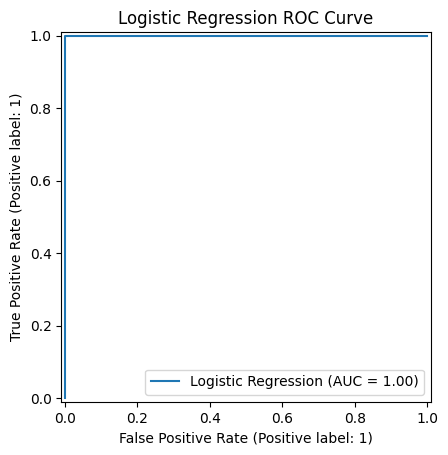

In [40]:
# Part 24: Plot the ROC Curve

from sklearn.metrics import (
    RocCurveDisplay
)

RocCurveDisplay.from_predictions(
    y_test,
    lr_prob,
    name="Logistic Regression"
)

plt.title(
    "Logistic Regression ROC Curve"
)

plt.show()

In [41]:
# Part 25: Start Your Final Model Comparison Table

model_results = pd.DataFrame([
    {
        "Model":
            "Logistic Regression",

        "Accuracy":
            lr_accuracy,

        "Precision":
            lr_precision,

        "Recall":
            lr_recall,

        "F1-score":
            lr_f1,

        "ROC-AUC":
            lr_auc
    }
])

model_results

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.999894,1.0,0.999752,0.999876,1.0


# Week 5: Decision Tree Phishing Detection


In [42]:
# Part 8: Import DecisionTreeClassifier

from sklearn.tree import DecisionTreeClassifier


In [43]:
# Part 9: Build the Decision Tree

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)


In [44]:
# Part 10: Train the Decision Tree

dt_model.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [45]:
# Part 11: Generate Predictions

dt_pred = dt_model.predict(
    X_test
)

print(
    dt_pred[:20]
)


[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


In [46]:

# Part 12: Check the Actual Tree Depth

print(
    dt_model.get_depth()
)

print(
    dt_model.get_n_leaves()
)


4
5


In [47]:

# Part 13: Evaluate the Decision Tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

dt_precision = precision_score(
    y_test,
    dt_pred
)

dt_recall = recall_score(
    y_test,
    dt_pred
)

dt_f1 = f1_score(
    y_test,
    dt_pred
)

print(
    f"Accuracy : {dt_accuracy:.4f}"
)

print(
    f"Precision: {dt_precision:.4f}"
)

print(
    f"Recall   : {dt_recall:.4f}"
)

print(
    f"F1-score : {dt_f1:.4f}"
)


Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


In [48]:
# Part 15: Create the Confusion Matrix

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_test,
    dt_pred
)

print(cm)

[[26970     0]
 [    0 20189]]


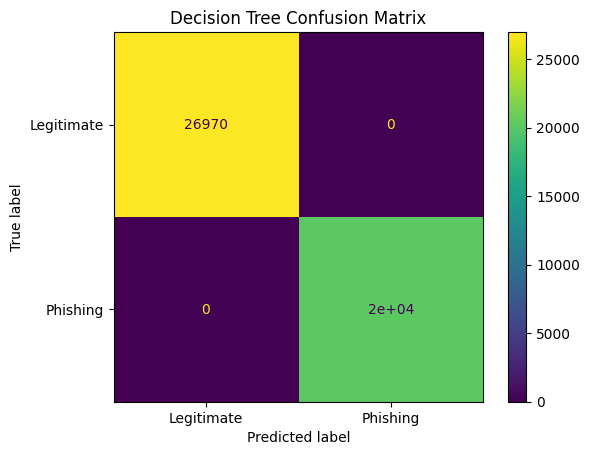

In [49]:
# Part 16: Display the Confusion Matrix

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Phishing"
    ]
).plot()

plt.title(
    "Decision Tree Confusion Matrix"
)

plt.show()

In [50]:

# Part 18: Training Performance vs. Testing Performance

train_accuracy = dt_model.score(
    X_train,
    y_train
)

test_accuracy = dt_model.score(
    X_test,
    y_test
)

print(
    "Training accuracy:",
    train_accuracy
)

print(
    "Testing accuracy:",
    test_accuracy
)


Training accuracy: 1.0
Testing accuracy: 1.0


# Homework 5: Decision Tree Phishing Detection

In [51]:
# Part 1: Prepared Data
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (188636, 50)
X_test : (47159, 50)
y_train: (188636,)
y_test : (47159,)


In [52]:
# Part 2 — Verify the trained Decision Tree
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

dt_pred = dt_model.predict(
    X_test
)

print(
    dt_pred[:20]
)


[0 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 0 1 0 1]


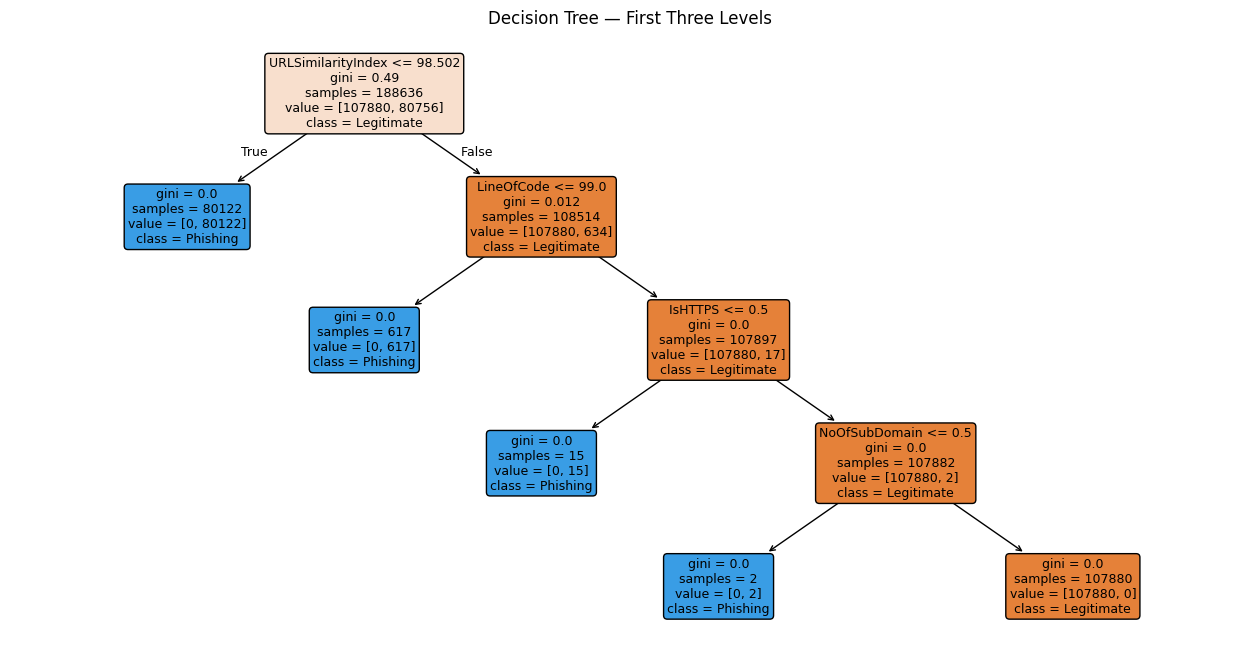

In [53]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

plot_tree(
    dt_model,
    max_depth=5,
    feature_names=X_train.columns,
    class_names=["Legitimate", "Phishing"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree — First Three Levels")
plt.show()

In [54]:
# Part 3: Evaluate the Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-score : {dt_f1:.4f}")

dt_results = pd.DataFrame({
    "Measure": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Your Result": [dt_accuracy, dt_precision, dt_recall, dt_f1]
})
print()
print("Homework 5 — Part 3 results table:")
print(dt_results.to_string(index=False, formatters={"Your Result": "{:.4f}".format}))

Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Homework 5 — Part 3 results table:
  Measure Your Result
 Accuracy      1.0000
Precision      1.0000
   Recall      1.0000
 F1-score      1.0000


In [55]:
# Part 4: Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    dt_pred
)

print(cm)

tn, fp, fn, tp = cm.ravel()
print(f"True negatives : {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives : {tp}")

[[26970     0]
 [    0 20189]]
True negatives : 26970
False positives: 0
False negatives: 0
True positives : 20189


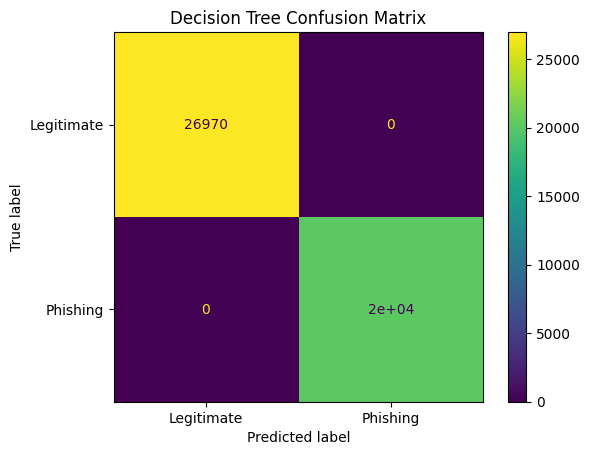

In [56]:
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
).plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

*   Question 1 — What does a true positive mean in this phishing-detection project?
  A true positive occurs when a URL that is actually phishing (class 1) is correctly classified by the Decision Tree as phishing. This represents a malicious website that the model successfully detects.
---

*   Question 2 — What does a false negative mean in this phishing-detection project?
  A false negative occurs when a URL that is actually phishing (class 1) is incorrectly classified as legitimate (class 0). In an operational security system, that error could allow an attacker-controlled website to evade detection and expose users to credential theft or malware.

## Part 5: Short Analysis
*   Question 1 — What is a Decision Tree?
A Decision Tree is a supervised machine-learning classifier that repeatedly divides examples based on feature values. At each decision node, it uses a condition, such as a threshold on URL length, to route an example toward a final leaf that predicts legitimate or phishing. These branching decisions allow it to model nonlinear relationships among cybersecurity features.
---

*   Question 2 — What does max_depth=5 control?
The max_depth parameter limits the maximum number of decision edges from the root to any leaf. Setting it to 5 prevents the model from creating arbitrarily long sequences of feature-based rules. This restriction controls complexity and can reduce overfitting, although a tree that is too shallow may underfit.
---

*   Question 3 — Why might a very deep Decision Tree overfit the training data?
A very deep Decision Tree can form highly specific branches for small numbers of training examples, learning noise or unusual patterns rather than general characteristics of phishing websites. Such a model may perform extremely well on training data but be less accurate when evaluating previously unseen URLs. Limiting tree depth is one technique for reducing this risk.
---

*   Question 4 — Which metric is especially important for phishing detection, and why?
I would prioritize recall because it measures the fraction of actual phishing URLs that the detector successfully identifies. Low recall means that more phishing websites are incorrectly labeled legitimate (false negatives), potentially allowing threats to reach users. Precision and F1-score are also important because excessive false alarms can reduce the usefulness of security alerts.

